# AdaBoost from scratch
Introduction to Machine Learning – Live coding

AdaBoost combines many **weak classifiers** (stumps = trees with one question) into one strong classifier. The stumps are trained **one after another**: each new stump focuses on the emails the previous ones got wrong, and better stumps get a bigger vote.

## 1. Imports

NumPy for arrays and calculations, Matplotlib for plots. Our AdaBoost uses **only NumPy**; sklearn is used later only to split the data and to compare.

In [335]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Toy data: phishing emails
10 emails, each described by 3 features: number of links, urgent words (1 = yes), sender known (1 = yes).
Label: **+1 = phishing, −1 = legit**. AdaBoost uses −1/+1 so that `label × prediction` is +1 when correct and −1 when wrong.
Email 5 is the hard case: only 1 link and a known sender, but it is phishing.

In [336]:
X_toy = np.array([
    [6, 1, 0],
    [4, 1, 0],
    [8, 0, 0],
    [5, 0, 1],
    [1, 1, 1],
    [0, 0, 1],
    [2, 0, 1],
    [3, 1, 1],
    [1, 0, 0],
    [2, 0, 1],
])
y_toy = np.array([1, 1, 1, 1, 1, -1, -1, -1, -1, -1])
features = ["num_links", "urgent_words", "sender_known"]
print(X_toy.shape)

(10, 3)


## 3. Weighted Gini
Measures how mixed a group is: **0 = pure**, **0.5 = completely mixed**. Formula: 1 − p² − (1 − p)².
In AdaBoost every email has a weight, so p is the **share of the weight** that belongs to phishing emails, not the share of the count. Heavy emails (the ones misclassified before) count more.

In [338]:
print(weighted_gini(np.array([1, 1, 1, -1]), np.ones(4)))
print(weighted_gini(np.array([1, 1, 1, -1]), np.array([1, 1, 1, 3])))

0.375
0.5


## 4. Best stump
A stump is a decision tree with **one question**: "feature < threshold?".
We try every feature and every threshold (midpoints between sorted values), compute the weighted Gini of the two sides, and keep the question with the **lowest** score. Each side predicts the class with the most weight.

In [340]:
w = np.ones(10) / 10
stump = best_stump(X_toy, y_toy, w)
print("Question:", features[stump[0]], "<", stump[1])
print("Answer if yes:", stump [2], " answer if no:", stump[3])
print("Predictions:", predict_stump(stump, X_toy))
print("Real labels:", y_toy)

Question: num_links < 3.5
Answer if yes: -1  answer if no: 1
Predictions: [ 1  1  1  1 -1 -1 -1 -1 -1 -1]
Real labels: [ 1  1  1  1  1 -1 -1 -1 -1 -1]


## 5. AdaBoost
1. Start with **equal weights** 1/n.
2. Find the **best stump** using the weights.
3. **Error** e = sum of the weights of the wrong emails → **amount of say** α = ½ · log((1 − e) / e). Small error → big α.
4. **Update the weights**: w · e^(−α · y · prediction) → wrong emails get heavier, right ones lighter. Normalise so they add up to 1.
5. Repeat. **Prediction** = sign of the weighted vote Σ α · (stump prediction).

## 6. Check by hand
The first stump gets only email 5 wrong: e = 1/10 → α = ½ · log(9) = 1.10.
New weights: email 5: 0.1 · e^1.10 = 0.30, the others: 0.1 · e^−1.10 = 0.033 → after normalising: **0.5** and 0.056.
The misclassified email now holds half of all the weight, so the next stump focuses on it.

In [343]:
for n in [1, 2, 6]:
    model = AdaBoost(n_estimators=n).fit(X_toy, y_toy)
    print(n, "stumps:", model.predict(X_toy))
print("real:    ", y_toy)

1 stumps: [ 1  1  1  1 -1 -1 -1 -1 -1 -1]
2 stumps: [ 1  1  1  1 -1 -1 -1 -1 -1 -1]
6 stumps: [ 1  1  1  1  1 -1 -1 -1 -1 -1]
real:     [ 1  1  1  1  1 -1 -1 -1 -1 -1]


## 7. More emails
10 emails are too few to test a model, so we **simulate 300 emails** with the same 3 features (the first 10 are our toy emails).
Each email gets a "suspicion score": links and urgent words raise it, a known sender lowers it, plus random noise (like real emails, not all follow the rule). Score > 2 → phishing.

In [344]:
rng = np.random.default_rng(0)                       # random generator, seed 0 -> same emails every run
n = 290
num_links = rng.integers(0, 10, n)                   # 0 to 9 links
urgent = rng.integers(0, 2, n)                       # 0 or 1
known = rng.integers(0, 2, n)                        # 0 or 1
score = 0.5 * num_links + 1.5 * urgent - 2 * known + rng.normal(0, 1.5, n)   # suspicion score + noise
y_new = np.where(score > 2, 1, -1)                   # suspicious enough -> phishing
X = np.vstack([X_toy, np.column_stack([num_links, urgent, known])])   # our 10 emails on top of the 290
y = np.concatenate([y_toy, y_new])
print(X.shape, "phishing:", (y == 1).sum(), "legit:", (y == -1).sum())

(300, 3) phishing: 163 legit: 137


## 8. Comparison with sklearn
Split: **60% train** (to learn), **20% validation** (to choose hyperparameters), **20% test** (final score, used only once).
We train our AdaBoost and sklearn's AdaBoost with the same settings (30 stumps). The same accuracy shows our implementation is correct.

In [345]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
import time

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)  # 60% train
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp)  # 20% val, 20% test
print(X_train.shape, X_val.shape, X_test.shape)

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)  # share of correct predictions

(180, 3) (60, 3) (60, 3)


In [346]:
start = time.time()
ours = AdaBoost(n_estimators=30).fit(X_train, y_train)
our_time = time.time() - start

start = time.time()
sk = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=30, random_state=0).fit(X_train, y_train)  # max_depth=1 -> stumps, like ours
sk_time = time.time() - start

print(f"Our AdaBoost:     accuracy = {accuracy(y_test, ours.predict(X_test)):.3f}   time = {our_time:.2f}s")
print(f"sklearn AdaBoost: accuracy = {accuracy(y_test, sk.predict(X_test)):.3f}   time = {sk_time:.2f}s")

Our AdaBoost:     accuracy = 0.850   time = 0.22s
sklearn AdaBoost: accuracy = 0.850   time = 0.39s


## 9. Hyperparameter analysis
The main hyperparameter of AdaBoost is the **number of stumps**. We compare accuracy on train and validation: too few stumps → **underfitting**; a growing gap between train and validation → **overfitting**.
We also plot the **amount of say (α)** of each stump, and finally test the best number of stumps (chosen on validation) **once** on the test set.

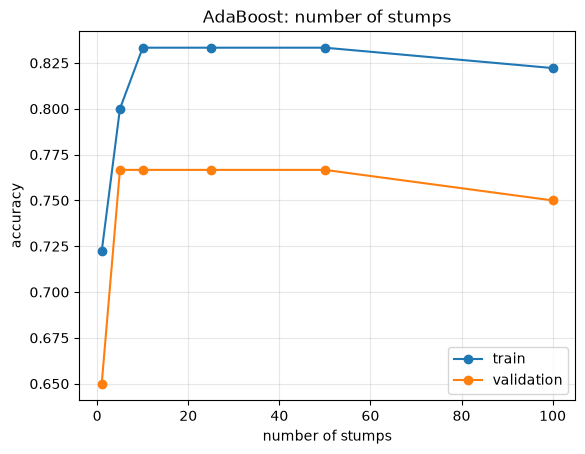

In [347]:
n_list = [1, 5, 10, 25, 50, 100]
train_acc, val_acc = [], []
for n in n_list:
    m = AdaBoost(n_estimators=n).fit(X_train, y_train)
    train_acc.append(accuracy(y_train, m.predict(X_train)))
    val_acc.append(accuracy(y_val, m.predict(X_val)))

plt.plot(n_list, train_acc, "o-", label="train")
plt.plot(n_list, val_acc, "o-", label="validation")
plt.xlabel("number of stumps"); plt.ylabel("accuracy"); plt.title("AdaBoost: number of stumps")
plt.legend(); plt.grid(alpha=0.3); plt.show()

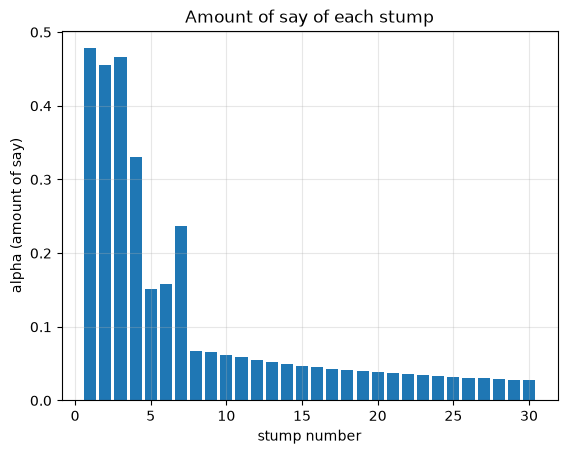

In [348]:
plt.bar(range(1, len(ours.alphas) + 1), ours.alphas)  # one bar per stump: its amount of say
plt.xlabel("stump number"); plt.ylabel("alpha (amount of say)"); plt.title("Amount of say of each stump")
plt.grid(alpha=0.3); plt.show()

In [349]:
best_n = n_list[np.argmax(val_acc)]  # number of stumps with the best validation accuracy
final = AdaBoost(n_estimators=best_n).fit(X_train, y_train)
print("Best number of stumps (validation):", best_n)
print("Test accuracy:", round(accuracy(y_test, final.predict(X_test)), 3))

Best number of stumps (validation): 5
Test accuracy: 0.833
